# Horizontal light extinction over the sea

This notebook estimates how much light from an LED lamp survives a 1–2 km horizontal path through a marine aerosol layer.

libRadtran is a 1D plane-parallel model: its sources are the sun or thermal emission, and all paths are slanted through horizontally homogeneous layers. It has no point source and no purely horizontal path. It does know the aerosol and molecular extinction coefficient of every layer at every wavelength, and for a homogeneous layer that is all a horizontal Beer–Lambert calculation needs.

The method:

1. Put the sun at the zenith (`sza = 0`), so the direct beam travels straight down.
2. Output the direct irradiance $E_\mathrm{dir}$ at two levels $z_1 < z_2$ bracketing the lamp height.
3. The layer's volume extinction coefficient is

$$
\beta_\mathrm{ext}(\lambda) = \frac{\ln E_\mathrm{dir}(z_2, \lambda) - \ln E_\mathrm{dir}(z_1, \lambda)}{z_2 - z_1}
$$

4. The horizontal transmission over a distance $L$ at that height is

$$
T(\lambda, L) = \exp\left(-\beta_\mathrm{ext}(\lambda)\,L\right)
$$

$\beta_\mathrm{ext}$ contains aerosol extinction, Rayleigh scattering and gas absorption, all from the same optical properties libRadtran would use in a full radiative-transfer run.

In [1]:
import pyradtran  # Registers the .pyradtran xarray accessor
from pyradtran import Var
from pyradtran import load_config
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pathlib import Path
import pandas as pd
import logging

# Show warnings only (set to DEBUG to see every uvspec call)
logging.getLogger('pyradtran').setLevel(logging.WARNING)

## Configuration

Only the direct beam matters here, so the solver choice barely affects the result; `disort` is used for consistency with the other notebooks. `reptran fine` resolves gas absorption at 1 nm, and `sza = 0` overrides the solar position calculated from time and location.

In [2]:
cfg = load_config()
cfg.simulation_defaults.rte_solver           = "disort"
cfg.simulation_defaults.mol_abs_param        = "reptran fine"
cfg.simulation_defaults.source               = "solar"
cfg.simulation_defaults.wavelength_nm        = [400, 750]
cfg.simulation_defaults.integrate_wavelength = False
cfg.simulation_defaults.sza                  = 0.0
cfg.simulation_defaults.output_columns       = ["edir"]
cfg.execution.max_workers                    = 8
config_path = Path("config/led_extinction.yaml")
cfg.to_yaml(config_path)

print(f"Config: {config_path}")

Config: config/led_extinction.yaml


## Visibility scenarios

The visibility is a sweep dimension of the input dataset, from hazy (5 km) to clear (50 km), and is passed to libRadtran per point with `Var`.

The two altitude levels (0 and 100 m) bracket a lamp mounted a few metres above the sea surface. The location is a North Sea coordinate; with `sza` fixed it only matters for the day of year.

In [3]:
visibility_km = [5, 10, 20, 50]
N_scenarios = len(visibility_km)

ds = xr.Dataset(
    coords={
        'time'      : [pd.Timestamp('2025-06-21T12:00:00')],
        'latitude'  : ('time', [54.2]),
        'longitude' : ('time', [7.9]),
        'visibility': ('visibility', visibility_km, {'units': 'km'}),   # sweep axis
        'altitude'  : ('altitude', [0.0, 0.1]),  # km, brackets the lamp height
    },
)
ds['vis_km'] = ds.visibility   # variable for Var() to reference

ds

<xarray.Dataset> Size: 104B
Dimensions:     (time: 1, visibility: 4, altitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 8B 2025-06-21T12:00:00
    latitude    (time) float64 8B 54.2
    longitude   (time) float64 8B 7.9
  * visibility  (visibility) int64 32B 5 10 20 50
  * altitude    (altitude) float64 16B 0.0 0.1
Data variables:
    vis_km      (visibility) int64 32B 5 10 20 50

## Run: maritime aerosol and clean air

`aerosol_default` switches on the Shettle (1989) aerosol model, `aerosol_haze 4` selects the maritime boundary-layer type, and `aerosol_visibility` scales its extinction to the requested visibility.

A second run without aerosol gives the molecular (Rayleigh + gas) background.

In [4]:
ds_aer = ds.pyradtran.run(
    config_path=config_path,
    return_dataset=True,
    save_to_file=False,
    params={
        'aerosol_default'   : True,   # flag option
        'aerosol_haze'      : 4,  # maritime
        'aerosol_visibility': Var('vis_km'),
    },
    show_progress=False,
)

ds_clean = ds.isel(visibility=[0]).drop_vars('vis_km').pyradtran.run(
    config_path=config_path,
    return_dataset=True,
    save_to_file=False,
    show_progress=False,
)

ds_aer

<xarray.Dataset> Size: 25kB
Dimensions:     (time: 1, visibility: 4, wavelength: 351, altitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 8B 2025-06-21T12:00:00
  * visibility  (visibility) int64 32B 5 10 20 50
  * wavelength  (wavelength) float64 3kB 400.0 401.0 402.0 ... 748.0 749.0 750.0
  * altitude    (altitude) float64 16B 0.0 0.1
Data variables:
    edir        (time, visibility, wavelength, altitude) float64 22kB 241.1 ....
    status      (time, visibility) int64 32B 0 0 0 0
Attributes:
    generated_by:              pyradtran
    generation_date:           2026-11-14T14:20:47.244668
    pyradtran_version:         0.2.0
    history:                   2026-11-14T14:20:47: pyradtran 0.2.0 ds.pyradt...
    pyradtran_params:          {"aerosol_default": true, "aerosol_haze": 4, "...
    pyradtran_libradtran_bin:  /opt/libRadtran-2.0.6/bin/uvspec
    pyradtran_config:          paths: {libradtran_bin: /opt/libRadtran-2.0.6/...
    pyradtran_input_example:   rte_solver disort                             ...

## Extinction coefficient

Applying the log-difference formula to the direct irradiance gives $\beta_\mathrm{ext}$ in km⁻¹.

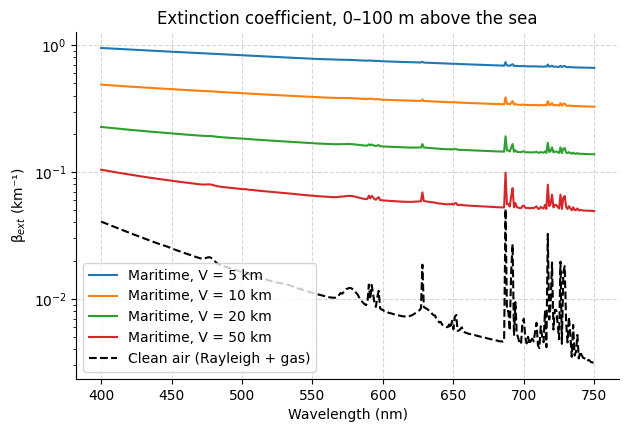

In [5]:
def extinction_coefficient(ds_sim):
    """Volume extinction coefficient (km⁻¹) of the layer between the two zout levels."""
    z1, z2 = ds_sim.altitude.values
    beta = (np.log(ds_sim.edir.sel(altitude=z2)) - np.log(ds_sim.edir.sel(altitude=z1))) / (z2 - z1)
    return beta.rename('beta_ext').assign_attrs(units='km-1', long_name='Extinction coefficient')

beta_aer   = extinction_coefficient(ds_aer).squeeze('time', drop=True)
beta_clean = extinction_coefficient(ds_clean).squeeze(drop=True)

fig, ax = plt.subplots(figsize=(7, 4.5))

for vis in visibility_km:
    beta_aer.sel(visibility=vis).plot(ax=ax, lw=1.5, label=f'Maritime, V = {vis} km')
beta_clean.plot(ax=ax, color='black', ls='--', lw=1.5, label='Clean air (Rayleigh + gas)')

ax.set_yscale('log')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('β$_{ext}$ (km⁻¹)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('Extinction coefficient, 0–100 m above the sea')
plt.show()

### Sanity check: Koschmieder

Meteorological visibility is defined through the Koschmieder relation $V = 3.912 / \beta_\mathrm{ext}(550\,\mathrm{nm})$. Converting the simulated extinction back to a visibility shows how closely the aerosol profile follows the requested visibility near the surface.

In [6]:
beta_550 = beta_aer.sel(wavelength=550)

pd.DataFrame({
    'input visibility (km)'     : visibility_km,
    'β_ext at 550 nm (km⁻¹)'   : beta_550.values.round(4),
    'Koschmieder 3.912/β (km)'  : (3.912 / beta_550.values).round(2),
})

,input visibility (km),β_ext at 550 nm (km⁻¹),Koschmieder 3.912/β (km)
0,5,0.7811,5.01
1,10,0.3901,10.03
2,20,0.1686,23.20
3,50,0.0650,60.19


The input visibility is recovered to within 1 % at 5 and 10 km. For clearer air it is not: the extinction libRadtran's Shettle (1989) profile puts into the lowest 100 m is 14 % (20 km) and 17 % (50 km) below the Koschmieder value, which reads back as 23 km and 60 km. Treat `aerosol_visibility` as a scenario setting and use the simulated $\beta_\mathrm{ext}$, not the nominal visibility, for the transmission.

## LED transmission over 0–2 km

LEDs are not monochromatic. Each lamp is modelled as a Gaussian emission line (peak wavelength, FWHM), which weights the spectral transmission:

$$
T_\mathrm{LED}(L) = \frac{\int S(\lambda)\, e^{-\beta_\mathrm{ext}(\lambda) L}\, d\lambda}{\int S(\lambda)\, d\lambda}
$$

For real lamps, replace the Gaussians with measured LED spectra.

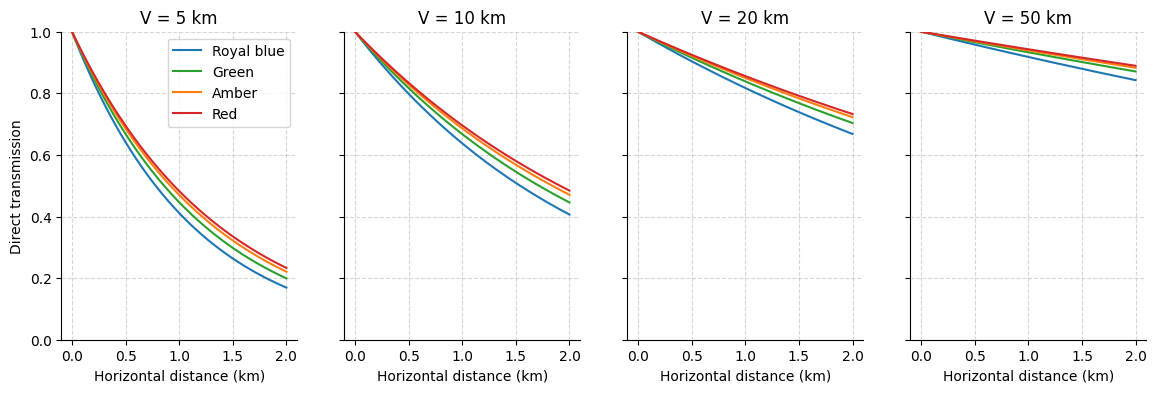

In [7]:
# ── LED emission spectra: peak (nm), FWHM (nm) ───────────────────────────────
leds = {
    'Royal blue': (450, 20, 'tab:blue'),
    'Green'     : (525, 30, 'tab:green'),
    'Amber'     : (590, 15, 'tab:orange'),
    'Red'       : (630, 18, 'tab:red'),
}

wavelength = beta_aer.wavelength
distance_km = xr.DataArray(np.linspace(0, 2, 101), dims='distance', attrs={'units': 'km'})

def led_spectrum(peak_nm, fwhm_nm):
    sigma = fwhm_nm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-0.5 * ((wavelength - peak_nm) / sigma) ** 2)

def led_transmission(beta, peak_nm, fwhm_nm):
    s = led_spectrum(peak_nm, fwhm_nm)
    return (s * np.exp(-beta * distance_km)).sum('wavelength') / s.sum('wavelength')

transmission = xr.concat(
    [led_transmission(beta_aer, peak, fwhm) for peak, fwhm, _ in leds.values()],
    dim=pd.Index(list(leds), name='led'),
).assign_coords(distance=distance_km)

fig, axes = plt.subplots(1, N_scenarios, figsize=(14, 4), sharey=True)

for ax, vis in zip(axes, visibility_km):
    for name, (_, _, color) in leds.items():
        transmission.sel(led=name, visibility=vis).plot(ax=ax, color=color, lw=1.5, label=name)
    ax.set_title(f'V = {vis} km')
    ax.set_xlabel('Horizontal distance (km)')
    ax.set_ylabel('')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.5)

axes[0].set_ylabel('Direct transmission')
axes[0].legend()
axes[0].set_ylim(0, 1)
plt.show()

In [8]:
# Direct transmission at 1 and 2 km
(
    transmission.sel(distance=[1.0, 2.0])
    .to_series()
    .unstack(['visibility', 'distance'])
    .round(3)
)

visibility     5             10            20            50       
distance      1.0    2.0    1.0    2.0    1.0    2.0    1.0    2.0
led                                                               
Royal blue  0.411  0.169  0.638  0.406  0.817  0.668  0.918  0.843
Green       0.446  0.199  0.668  0.446  0.839  0.704  0.933  0.871
Amber       0.470  0.221  0.686  0.471  0.850  0.723  0.940  0.883
Red         0.483  0.233  0.696  0.484  0.856  0.733  0.943  0.889

### Interpretation

- Aerosol dominates. Even at 50 km visibility the total extinction is about 2.5 times the molecular background at 400 nm and nearly ten times at 650 nm; at 5–10 km the aerosol is larger by more than an order of magnitude at all wavelengths.
- Red goes farthest. Extinction decreases with wavelength, so red and amber LEDs keep more of their direct beam than blue ones. The spectral difference in $\beta_\mathrm{ext}$ is multiplied by the path length, so the colour gap widens in haze and over longer distances.
- Transmission falls exponentially with distance. Doubling the path from 1 to 2 km squares the transmission: at 5 km visibility a 2 km path passes only about a fifth of the direct beam.

## Limitations and options

- Direct beam only. $T$ is the Beer–Lambert (unscattered) transmission. Maritime aerosol scatters strongly forward, so a detector with a wide field of view also collects forward-scattered light and sees more than $T$. For a narrow-FOV receiver or path optical depths $\beta L \lesssim 1$, the direct beam is the relevant quantity.
- Homogeneous path. The lamp and receiver sit in the same model layer. For different heights, add more `altitude` levels and integrate $\beta_\mathrm{ext}(z)$ along the slant path.
- Aerosol model. `aerosol_haze` also offers rural (1), urban (5) and tropospheric (6) types. For OPAC mixtures (e.g. `maritime_clean`, `maritime_polluted`) use `aerosol_species_file`; humidity growth of sea salt then follows the atmosphere's relative humidity.
- Measured aerosol. With measured AOD or extinction profiles, `aerosol_file tau`, `aerosol_angstrom` and `aerosol_modify` take over from the visibility scaling.